# 08 — Response Quality and Operational Playbook

> **Which complaint segments deserve the first hour of an analyst's day?**

| | |
|---|---|
| **Audience** | Operations leads, queue managers |
| **Owner** | CX Complaint Intelligence team |
| **Status** | Reference implementation (portfolio sample) |
| **Last reviewed** | 2026-05-25 |
| **Runtime** | ~15 s on the bundled sample |
| **Reproduces from** | `data/raw/cfpb_sample.csv` |

## Business question

Which segments combine high heuristic risk, untimely response, and a weak response code &mdash; the operational definition of a priority-review queue?

## How to read this notebook

1. Section **0** initialises the environment and loads data.
2. Sections **1-N** build the analysis tables and visuals.
3. The **Insights** section is generated from the computed tables &mdash; it does not contain hand-written claims.
4. The **Limitations** section flags known caveats before stakeholders act on the numbers.
5. The **Exports** section persists every table and figure under `reports/notebook/08/` so the output is auditable.


## 0. Setup

This cell:

- locates the project root from wherever the kernel was started;
- applies the shared matplotlib house style and pandas display options;
- creates the artefact directory `reports/notebook/08/`;
- captures the Python and library versions used for this run.


In [1]:
from __future__ import annotations

import warnings
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cx_complaints.reports.notebook_utils import (
    PALETTE,
    RISK_COLORS,
    concentration_table,
    horizontal_bar,
    kpi_table,
    load_complaints,
    load_pipeline_outputs,
    monthly_summary,
    render_environment,
    save_figure,
    save_table,
    setup_notebook,
    topic_labels,
    write_environment_snapshot,
)

warnings.filterwarnings("ignore", category=FutureWarning)

ctx = setup_notebook("08")
render_environment(ctx)


,field,value
0,python,3.12.11
1,platform,Windows-11-10.0.26200-SP0
2,numpy,2.4.6
3,pandas,2.3.3
4,matplotlib,3.10.9
5,scikit-learn,1.8.0
6,project_root,C:\Users\diogo\work_code\portfolio\cx-complain...
7,notebook_id,08


## 1. Load and tag response quality

In [2]:
complaints = load_complaints(ctx)
complaints["timely_is_yes"] = complaints["timely"].fillna("").astype(str).str.lower() == "yes"
complaints["weak_response"] = (
    complaints["company_response"].fillna("").astype(str).str.lower().isin(
        ["closed", "closed with explanation", "in progress"]
    )
)
complaints[["complaint_id", "timely", "company_response", "timely_is_yes", "weak_response"]].head()

,complaint_id,timely,company_response,timely_is_yes,weak_response
0,9316329,Yes,Closed with explanation,True,True
1,9282035,Yes,Closed with explanation,True,True
2,9265219,Yes,Closed with non-monetary relief,True,False
3,9333110,Yes,Closed with non-monetary relief,True,False
4,9357247,Yes,Closed with explanation,True,True


## 2. Response segmentation

In [3]:
response_segment = (
    complaints.assign(
        timely_clean=complaints["timely"].fillna("Unknown").astype(str).str.title(),
        response_clean=complaints["company_response"].fillna("Unknown").astype(str).str.title(),
    )
    .groupby(["timely_clean", "response_clean"], as_index=False)
    .agg(
        complaints=("complaint_id", "size"),
        avg_risk_score=("risk_score", "mean"),
        high_risk_share_pct=("risk_level", lambda s: (s == "high").mean() * 100),
    )
    .sort_values(["complaints", "avg_risk_score"], ascending=[False, False])
)
response_segment["avg_risk_score"] = response_segment["avg_risk_score"].round(2)
response_segment["high_risk_share_pct"] = response_segment["high_risk_share_pct"].round(1)
response_segment.head(15)

,timely_clean,response_clean,complaints,avg_risk_score,high_risk_share_pct
1,Yes,Closed With Explanation,502,3.40,12.70
3,Yes,Closed With Non-Monetary Relief,487,3.52,14.60
2,Yes,Closed With Monetary Relief,10,2.72,0.00
0,No,Untimely Response,1,5.75,100.00


## 3. Build the priority queue

In [4]:
priority_queue = complaints[
    (complaints["risk_level"] == "high")
    & (~complaints["timely_is_yes"])
    & (complaints["weak_response"])
].copy()
priority_queue = priority_queue.sort_values("risk_score", ascending=False)

kpi = pd.DataFrame({
    "metric": [
        "Total complaints",
        "High-risk complaints",
        "Untimely complaints",
        "Weak-response complaints",
        "Priority queue (intersection)",
    ],
    "count": [
        len(complaints),
        int((complaints["risk_level"] == "high").sum()),
        int((~complaints["timely_is_yes"]).sum()),
        int(complaints["weak_response"].sum()),
        len(priority_queue),
    ],
})
kpi["share_pct"] = (kpi["count"] / max(len(complaints), 1) * 100).round(2)
kpi

,metric,count,share_pct
0,Total complaints,1000,100.00
1,High-risk complaints,136,13.60
2,Untimely complaints,1,0.10
3,Weak-response complaints,502,50.20
4,Priority queue (intersection),0,0.00


## 4. Top priority items

In [5]:
preview = priority_queue[[
    "complaint_id", "date_received", "company", "product", "issue",
    "company_response", "timely", "risk_score",
]].head(25)
preview

,complaint_id,date_received,company,product,issue,company_response,timely,risk_score


## 5. Where the priority queue concentrates

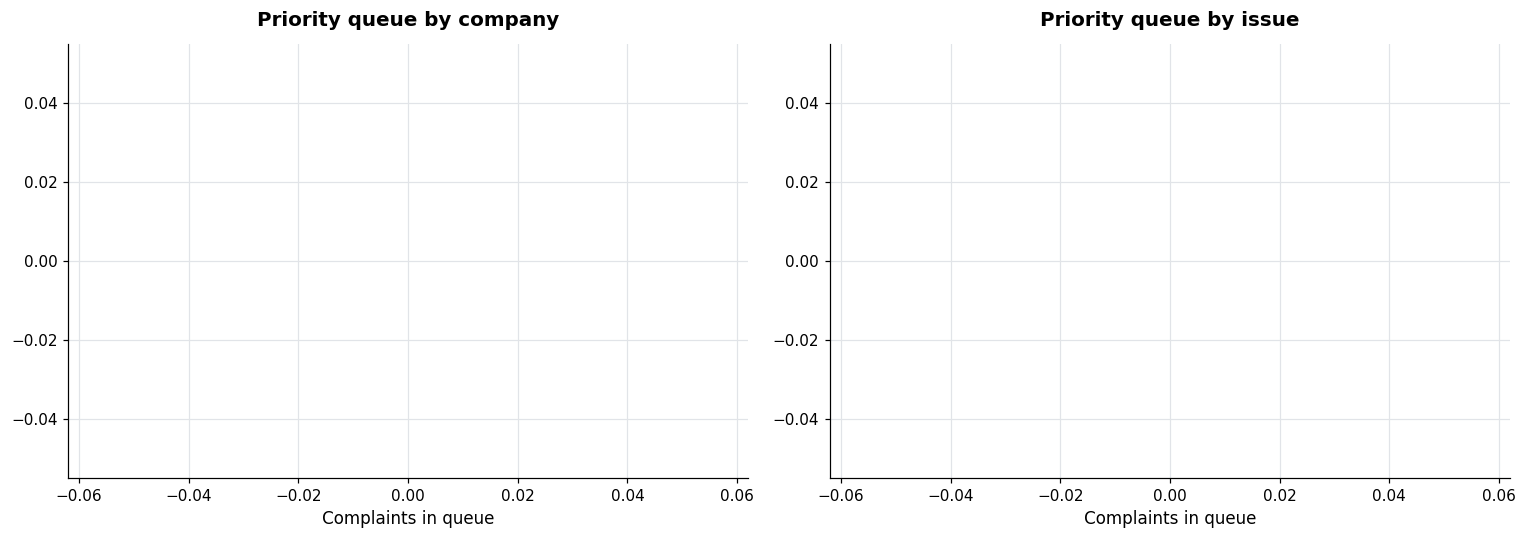

In [6]:
queue_company = (
    priority_queue.groupby("company", dropna=False, as_index=False)
    .size().rename(columns={"size": "complaints"}).sort_values("complaints", ascending=False)
)
queue_issue = (
    priority_queue.groupby("issue", dropna=False, as_index=False)
    .size().rename(columns={"size": "complaints"}).sort_values("complaints", ascending=False)
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_company = queue_company.head(10)
top_issue = queue_issue.head(10)
horizontal_bar(
    axes[0],
    top_company["company"].fillna("Unknown").astype(str).str.slice(0, 40),
    top_company["complaints"],
    color=PALETTE["warning"],
)
axes[0].set_title("Priority queue by company")
axes[0].set_xlabel("Complaints in queue")
horizontal_bar(
    axes[1],
    top_issue["issue"].fillna("Unknown").astype(str).str.slice(0, 40),
    top_issue["complaints"],
    color=PALETTE["accent"],
)
axes[1].set_title("Priority queue by issue")
axes[1].set_xlabel("Complaints in queue")
fig.tight_layout()
save_figure(ctx, fig, "priority_queue_concentration")
plt.show()

## 6. Operational playbook & insights

In [7]:
queue_share = float(kpi.loc[kpi["metric"] == "Priority queue (intersection)", "share_pct"].iloc[0])
top_queue_company = queue_company.iloc[0] if not queue_company.empty else None
top_queue_issue = queue_issue.iloc[0] if not queue_issue.empty else None
lines = [
    f"- **Priority queue size**: {len(priority_queue):,} complaints "
    f"({queue_share:.2f}% of total).",
]
if top_queue_company is not None:
    lines.append(
        f"- **Highest-volume queued company**: {top_queue_company['company']} "
        f"({int(top_queue_company['complaints'])} queued complaints)."
    )
if top_queue_issue is not None:
    lines.append(
        f"- **Most-common queued issue**: {top_queue_issue['issue']} "
        f"({int(top_queue_issue['complaints'])} queued complaints)."
    )
lines.extend([
    "- **Daily routine**: open this notebook, sort by `risk_score`, work top-down.",
    "- **Weekly routine**: track queue volume per company &mdash; an escalation if growth > 25% WoW.",
    "- **Monthly routine**: pair the queue composition with the topic-trend notebook to spot themes.",
])
display(Markdown("\n".join(lines)))

- **Priority queue size**: 0 complaints (0.00% of total).
- **Daily routine**: open this notebook, sort by `risk_score`, work top-down.
- **Weekly routine**: track queue volume per company &mdash; an escalation if growth > 25% WoW.
- **Monthly routine**: pair the queue composition with the topic-trend notebook to spot themes.

## Limitations

- The risk score is heuristic, not a legal or regulatory finding. It exists to triage analyst attention.
- CFPB narratives are only published when the consumer consents, so coverage is partial.
- Company-level comparisons mix companies of very different sizes &mdash; always pair them with volume context.
- The sample bundled with this repo is a small subset of the public CFPB dataset and is meant for demonstration, not production decisions.

## Exports

All tables and figures generated above are saved under `reports/notebook/08/`. The environment snapshot is written alongside so a reader can reproduce the run.


In [8]:
save_table(ctx, response_segment, "response_segment")
save_table(ctx, kpi, "priority_queue_kpi")
save_table(ctx, priority_queue, "priority_queue")
save_table(ctx, queue_company, "priority_queue_company")
save_table(ctx, queue_issue, "priority_queue_issue")
write_environment_snapshot(ctx)
sorted(ctx.artefact_dir.iterdir())

[WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/08/environment.json'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/08/priority_queue.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/08/priority_queue_company.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/08/priority_queue_concentration.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/08/priority_queue_issue.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/08/priority_queue_kpi.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/08/response_segment.csv')]